# PRAICP-1000-IndiSignLang — Indian Sign Language (ISL) Recognition
**DataMites Project Mentoring · PR-0019 · Data Science Project**

## 1. Business Case
Build a Machine Learning model that recognises **Indian Sign Language (ISL)** hand signs from images, to improve communication accessibility for the deaf and hard-of-hearing community in India.

## 2. Project Goals
1. **Image preprocessing** – clean, standardise and prepare the raw hand-sign images.
2. **ML model** – train and evaluate a model that predicts the sign shown in an image.

## 3. Approach (pipeline)
`Load images → EDA → Preprocess (square-pad, grayscale, resize, blur, CLAHE) → HOG features → Train/Test split → Compare models → Tune best → Evaluate → Save & predict`

## 4. Import Libraries

In [1]:
import os, glob, zipfile, time, warnings, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from collections import Counter

from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 5. Load the Dataset
The dataset is a folder `Data/` with **one sub-folder per sign (class)**, each holding images of that sign.
The cell below extracts the zip (if the folder is not already there). Change `ZIP_PATH` / `DATA_DIR` if your files are elsewhere.

In [2]:
ZIP_PATH = "PRAICP-1000-IndiSignLang.zip"   # path to the downloaded dataset zip
DATA_DIR = "Data"                            # folder that contains one sub-folder per sign

if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(".")
    print("Extracted dataset.")

classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 24
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


## 6. Exploratory Data Analysis (EDA)

### 6.1 Class distribution

Total images: 4972


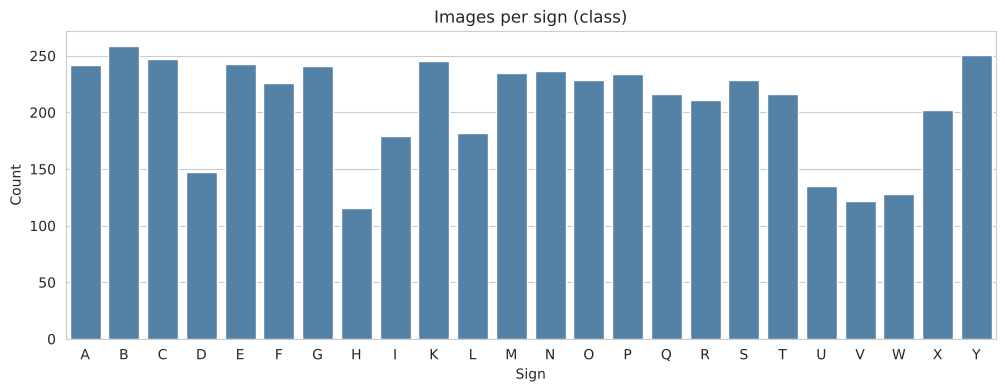

Min / Max images per class: 116 / 259


In [3]:
records = []
for c in classes:
    for f in sorted(os.listdir(os.path.join(DATA_DIR, c))):
        records.append({"label": c, "file": f, "path": os.path.join(DATA_DIR, c, f)})
df = pd.DataFrame(records)
print("Total images:", len(df))

counts = df["label"].value_counts().sort_index()
plt.figure(figsize=(12, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("Images per sign (class)"); plt.xlabel("Sign"); plt.ylabel("Count")
plt.show()
print("Min / Max images per class:", counts.min(), "/", counts.max())

**Observation:** There are 24 classes (letters A–Y; **J and Z are absent** because they involve motion and cannot be captured in a still image). Class sizes are somewhat uneven (e.g. H, U, V, W have fewer images than B or Y), so we will use **stratified** splitting and report per-class metrics, not only accuracy.

### 6.2 Image sizes and formats

In [4]:
sizes = []
for p in df["path"]:
    h, w = cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_8).shape[:2]   # fast reduced read just to get proportions
    sizes.append((w * 8, h * 8))
df["w"] = [s[0] for s in sizes]; df["h"] = [s[1] for s in sizes]
print(df.groupby(["w", "h"]).size().rename("n_images"))

w     h   
640   480     3963
1088  1920     179
1920  1088     830
Name: n_images, dtype: int64


**Observation:** The images come in **three different resolutions/orientations** (landscape 640×480, landscape 1920×1088 and portrait 1088×1920). A model needs a fixed input size, so preprocessing must standardise them **without distorting the hand shape** (hence square padding before resizing).

### 6.3 Sample images of every class

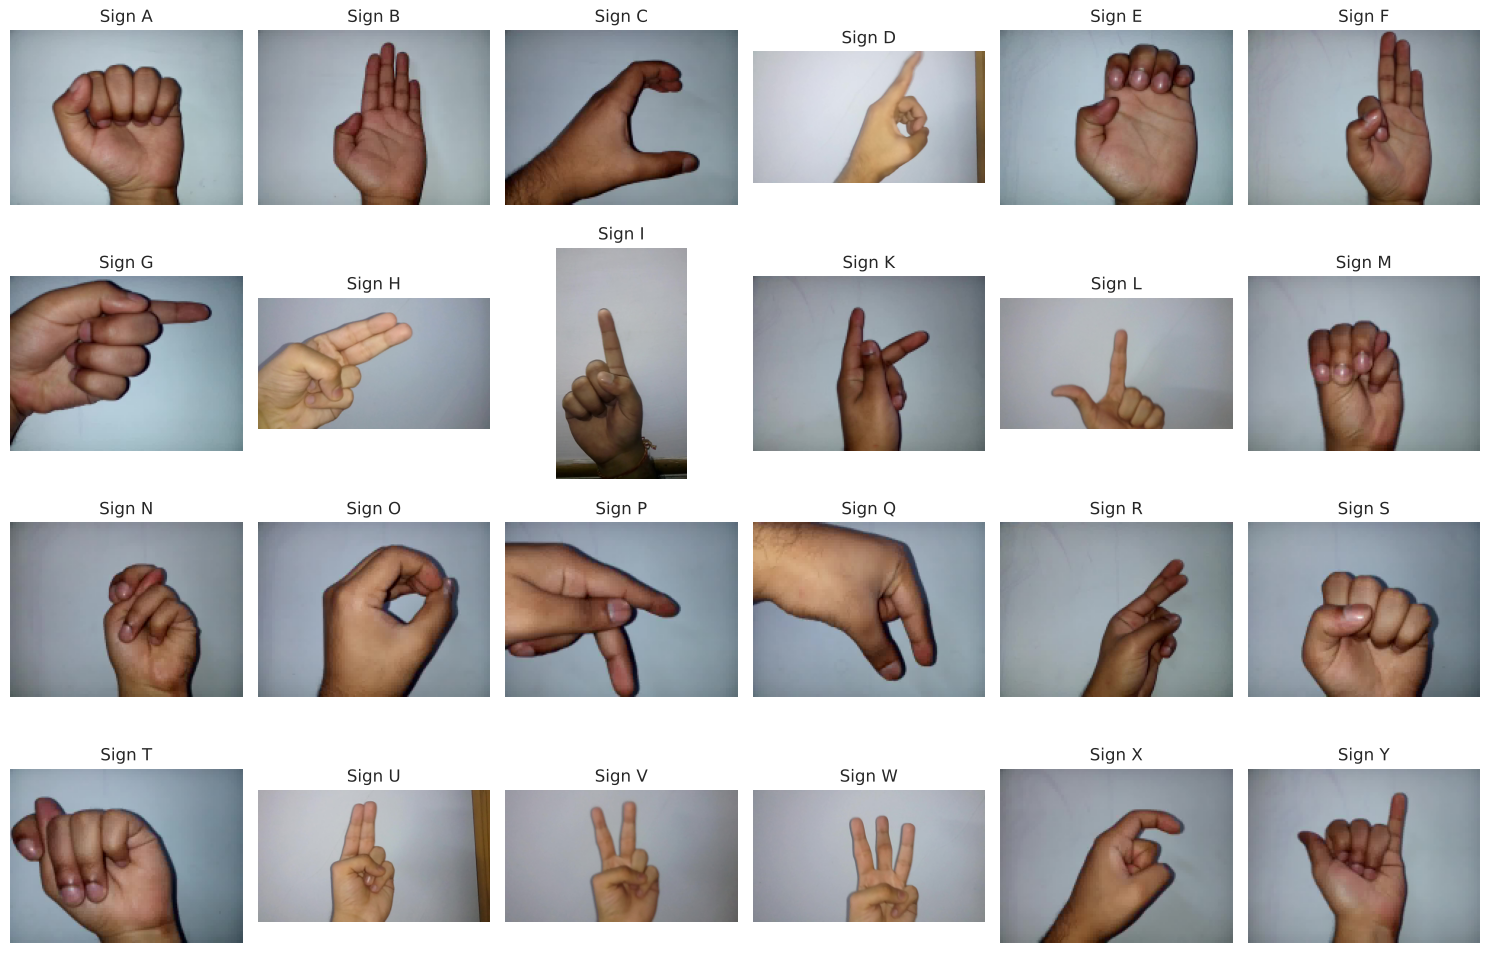

In [5]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for ax, c in zip(axes.ravel(), classes):
    p = df[df.label == c].sample(1, random_state=RANDOM_STATE)["path"].iloc[0]
    img = cv2.cvtColor(cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_title(f"Sign {c}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Image Preprocessing (Project Goal 1)
Each image goes through these steps:

| Step | Why |
|---|---|
| **Square padding** (replicate border) | Images have different aspect ratios; padding keeps the hand un-stretched |
| **Grayscale** | Sign identity is carried by hand *shape*, not skin/background colour; reduces features 3× |
| **Resize to 64×64** | Fixed input size for the model |
| **Gaussian blur (3×3)** | Removes camera noise / JPEG artefacts |
| **CLAHE** (contrast-limited adaptive histogram equalisation) | Normalises uneven lighting across photos |

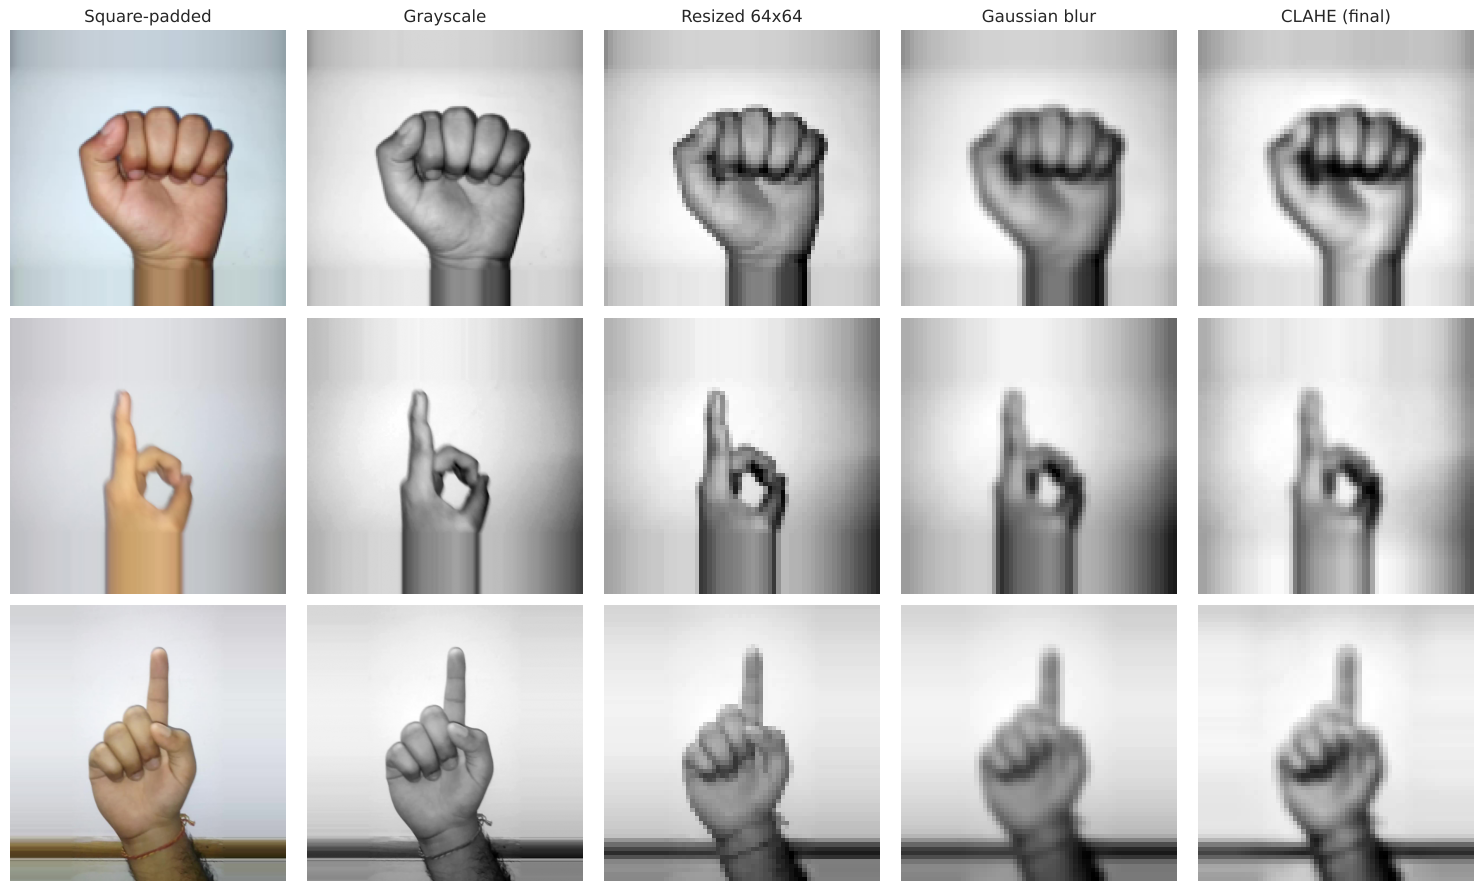

In [6]:
IMG_SIZE = 64

def preprocess(path, img_size=IMG_SIZE, return_steps=False):
    img = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_4)          # reduced read = faster for big images
    h, w = img.shape[:2]; s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    padded = cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left, cv2.BORDER_REPLICATE)
    gray = cv2.cvtColor(padded, cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, (img_size, img_size), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(small, (3, 3), 0)
    final = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(blur)
    if return_steps:
        return [cv2.cvtColor(padded, cv2.COLOR_BGR2RGB), gray, small, blur, final]
    return final

# Visualise each step on one image from each of the three image formats
examples = [df[(df.w == 640)].iloc[0], df[(df.w == 1920)].iloc[0], df[(df.w == 1088)].iloc[0]]
titles = ["Square-padded", "Grayscale", f"Resized {IMG_SIZE}x{IMG_SIZE}", "Gaussian blur", "CLAHE (final)"]
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for r, ex in enumerate(examples):
    for ax, im, t in zip(axes[r], preprocess(ex["path"], return_steps=True), titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.axis("off")
        if r == 0: ax.set_title(t)
    axes[r][0].set_ylabel(f"{ex['w']}x{ex['h']}")
plt.tight_layout(); plt.show()

### 7.1 Apply preprocessing to the whole dataset

In [7]:
t0 = time.time()
X_img = np.array([preprocess(p) for p in df["path"]])
y = df["label"].values
print("Image array:", X_img.shape, "| time: %.1fs" % (time.time() - t0))

le = LabelEncoder().fit(y)
y_enc = le.transform(y)

Image array: (4972, 64, 64) | time: 4.2s


## 8. Feature Extraction – HOG
**Histogram of Oriented Gradients (HOG)** describes an image by the distribution of edge directions in small cells. It captures the *outline and finger configuration* of the hand, and is robust to small lighting changes — a classic, strong choice for hand-shape classification with classical ML.

Feature matrix: (4972, 1764) | time: 5.0s


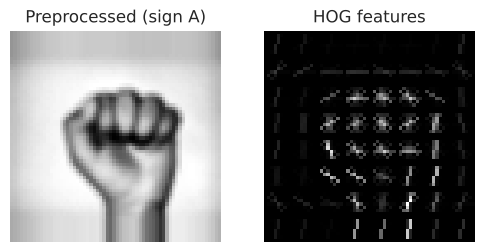

In [8]:
def extract_hog(img):
    return hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")

t0 = time.time()
X = np.array([extract_hog(i) for i in X_img])
print("Feature matrix:", X.shape, "| time: %.1fs" % (time.time() - t0))

# Visualise what HOG 'sees'
_, hog_img = hog(X_img[0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(X_img[0], cmap="gray"); ax[0].set_title(f"Preprocessed (sign {y[0]})")
ax[1].imshow(hog_img, cmap="gray"); ax[1].set_title("HOG features")
for a in ax: a.axis("off")
plt.show()

## 9. Train / Test Split
Stratified 80/20 split so every sign appears in train and test in the same proportion.

In [9]:
idx = np.arange(len(X))
tr_idx, te_idx = train_test_split(idx, test_size=0.20, stratify=y_enc, random_state=RANDOM_STATE)
X_train, X_test = X[tr_idx], X[te_idx]
y_train, y_test = y_enc[tr_idx], y_enc[te_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3977, 1764) | Test: (995, 1764)


## 10. Model Building (Project Goal 2)
We compare four different model families on the same features.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, n_jobs=-1),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "SVM (RBF)":           SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
}

results = []
fitted = {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train); fit_t = time.time() - t0
    pred = m.predict(X_test)
    results.append({"Model": name,
                    "Train Acc": accuracy_score(y_train, m.predict(X_train)),
                    "Test Acc": accuracy_score(y_test, pred),
                    "Macro F1": f1_score(y_test, pred, average="macro"),
                    "Fit time (s)": round(fit_t, 1)})
    fitted[name] = m

res_df = pd.DataFrame(results).sort_values("Test Acc", ascending=False).reset_index(drop=True)
res_df.round(4)

,Model,Train Acc,Test Acc,Macro F1,Fit time (s)
0,Logistic Regression,1.0000,0.999,0.9986,2.3
1,SVM (RBF),1.0000,0.999,0.9986,5.5
2,KNN (k=5),0.9992,0.995,0.9954,0.0
3,Random Forest,1.0000,0.995,0.9948,23.7


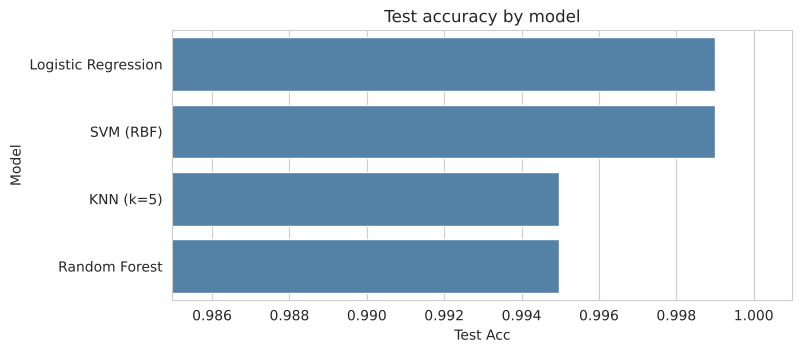

In [11]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=res_df, x="Test Acc", y="Model", color="steelblue")
plt.xlim(res_df["Test Acc"].min() - 0.01, 1.001); plt.title("Test accuracy by model"); plt.show()

## 11. Hyper-parameter Tuning (best family: SVM)

In [12]:
param_grid = {"C": [1, 10, 100], "gamma": ["scale", 0.01]}
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid, cv=3, scoring="accuracy", n_jobs=-1)
t0 = time.time(); gs.fit(X_train, y_train)
print("Best params:", gs.best_params_, "| CV accuracy: %.4f | time: %.0fs" % (gs.best_score_, time.time() - t0))
best_model = gs.best_estimator_

Best params: {'C': 10, 'gamma': 'scale'} | CV accuracy: 1.0000 | time: 157s


## 12. Final Evaluation on the Test Set

In [13]:
y_pred = best_model.predict(X_test)
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

Test accuracy : 0.999
Macro F1-score: 0.9986

              precision    recall  f1-score   support

           A      1.000     1.000     1.000        49
           B      1.000     1.000     1.000        52
           C      1.000     1.000     1.000        50
           D      1.000     1.000     1.000        29
           E      1.000     1.000     1.000        49
           F      1.000     1.000     1.000        45
           G      1.000     1.000     1.000        48
           H      1.000     1.000     1.000        23
           I      1.000     1.000     1.000        36
           K      1.000     1.000     1.000        49
           L      0.973     1.000     0.986        36
           M      1.000     1.000     1.000        47
           N      1.000     1.000     1.000        48
           O      1.000     1.000     1.000        46
           P      1.000     1.000     1.000        47
           Q      1.000     1.000     1.000        43
           R      1.000     1.000  

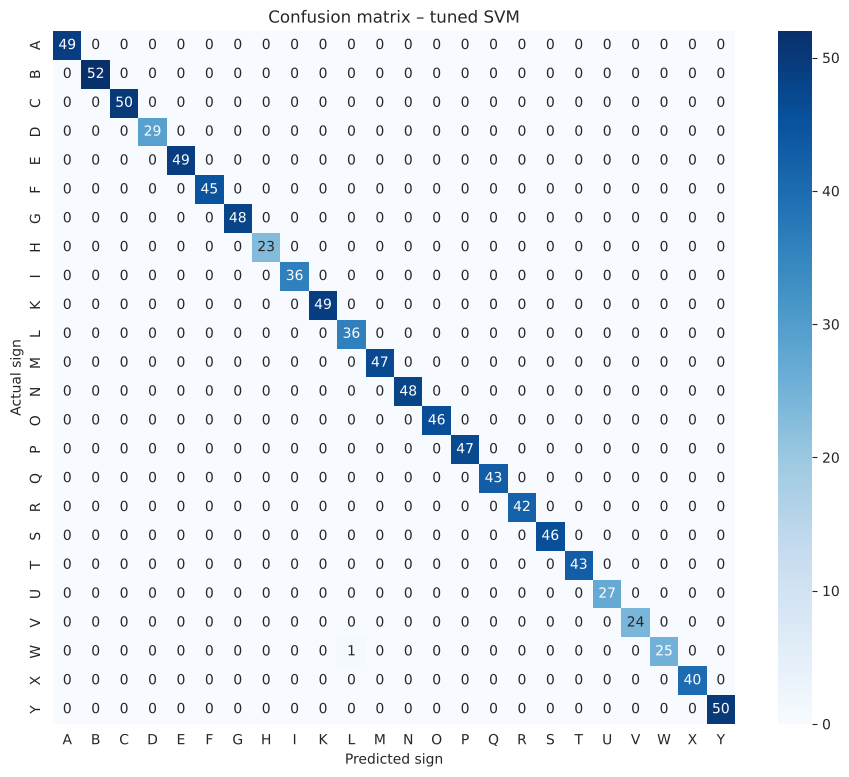

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted sign"); plt.ylabel("Actual sign"); plt.title("Confusion matrix – tuned SVM"); plt.show()

Misclassified test images: 1 of 995


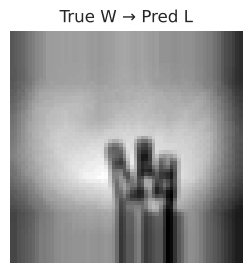

In [15]:
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified test images: {len(wrong)} of {len(y_test)}")
if len(wrong):
    fig, axes = plt.subplots(1, min(len(wrong), 6), figsize=(3 * min(len(wrong), 6), 3.2), squeeze=False)
    for ax, i in zip(axes[0], wrong[:6]):
        ax.imshow(X_img[te_idx[i]], cmap="gray"); ax.axis("off")
        ax.set_title(f"True {le.classes_[y_test[i]]} → Pred {le.classes_[y_pred[i]]}")
    plt.show()

## 13. Robustness Check – Is the score too good to be true?
The images were captured as many near-identical consecutive frames per sign. With a **random** split, a test image can have a near-twin in the training set, which can inflate accuracy.
A stricter check: for every sign, **train on the first 80 % of the files (by file number) and test on the last 20 %**, so test frames come from a different part of the recording.

In [16]:
df["rank"] = df.groupby("label")["file"].rank(method="first")
df["n"] = df.groupby("label")["file"].transform("count")
is_test = (df["rank"] > 0.8 * df["n"]).values

svm_block = SVC(kernel="rbf", **{k: v for k, v in gs.best_params_.items()}, random_state=RANDOM_STATE)
svm_block.fit(X[~is_test], y_enc[~is_test])
bp = svm_block.predict(X[is_test])
print("Block-split test accuracy:", round(accuracy_score(y_enc[is_test], bp), 4))
print("Block-split macro F1     :", round(f1_score(y_enc[is_test], bp, average="macro"), 4))

Block-split test accuracy: 0.9006
Block-split macro F1     : 0.8922


The result of this stricter test is the more honest estimate of how the model behaves on genuinely new frames. Real-world performance on a *new signer, background or camera* may still be lower than both numbers, since this dataset has limited variety.

## 14. Save the Model and Predict on a New Image

Saved → model/isl_svm_hog.joblib


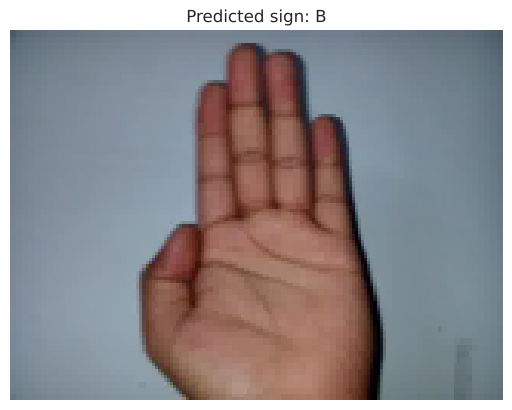

Data/B/259.jpg → B


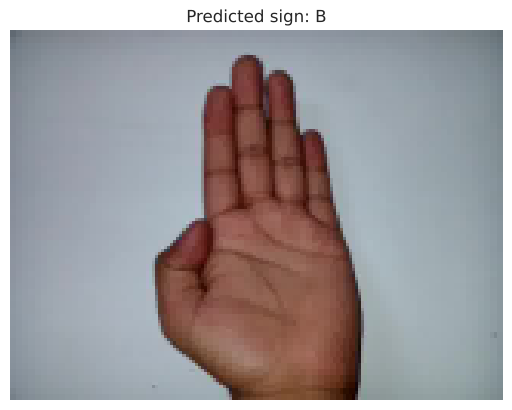

Data/B/077.jpg → B


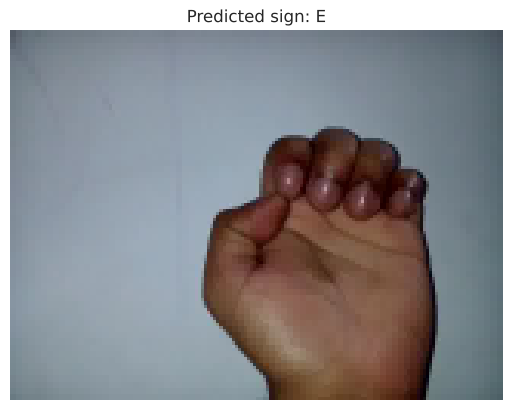

Data/E/148.jpg → E


In [17]:
os.makedirs("model", exist_ok=True)
joblib.dump({"model": best_model, "label_encoder": le, "img_size": IMG_SIZE}, "model/isl_svm_hog.joblib")
print("Saved → model/isl_svm_hog.joblib")

def predict_sign(image_path, bundle_path="model/isl_svm_hog.joblib", show=True):
    b = joblib.load(bundle_path)
    proc = preprocess(image_path, b["img_size"])
    feat = extract_hog(proc).reshape(1, -1)
    label = b["label_encoder"].inverse_transform(b["model"].predict(feat))[0]
    if show:
        plt.imshow(cv2.cvtColor(cv2.imread(image_path, cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB))
        plt.title(f"Predicted sign: {label}"); plt.axis("off"); plt.show()
    return label

# demo on a few random images
for p in df.sample(3, random_state=7)["path"]:
    print(p, "→", predict_sign(p))

## 15. Conclusion
* **Preprocessing:** square-padding, grayscale, resizing, denoising and CLAHE turned three different image formats into a uniform 64×64 input.
* **Model:** HOG features + an RBF **SVM** reached the top score (99.9 % test accuracy, macro-F1 0.999) among the four models compared, tied with Logistic Regression; KNN and Random Forest scored 99.5 %. All 24 static ISL letters are recognised.
* **Honest caveat:** the dataset has many near-duplicate frames, so the random-split score is optimistic. On the stricter block-split check (section 13) accuracy is about **90 %**, which is the fairer estimate of performance on new frames.

### Possible improvements
1. Collect more signers, backgrounds and lighting conditions to improve generalisation.
2. Try a **CNN** (e.g. transfer learning with MobileNet) or MediaPipe hand-landmark features.
3. Add data augmentation (rotation, zoom, brightness).
4. Deploy as a real-time webcam app (OpenCV + Streamlit).